# APID 21 exploration

After the housekeeping (APID 2), the fast int16 stream (APID 22) and the GPS text (APID 18), APID 21 is next: 697
packets of about 1.6 kB, all in three dumps (6, 8 and 10). Questions:

1. How is a packet laid out, and what is the cadence?
2. Is the data compressed, and can it be decoded?
3. Is it **LYRA**? The pasted LYRA description says the raw data is "interleaved time series packed in bit-level chunks
   that must be unpacked, sorted and decompressed", at a nominal 20 Hz, in four channels per unit.

In [1]:
from collections import Counter, defaultdict
from datetime import UTC, datetime, timedelta
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from sunpy.net import Fido
from sunpy.net import attrs as a
from sunpy.timeseries import TimeSeries

from cadu import iter_packets, packet_apid, packet_sequence_count

/Users/tedvtorov/Desktop/py-proj/new/proba-2_gif_generator/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CADU_DIR = Path("cadus")
APID = 21

# Packet layout, as found below: 6 byte primary header, the secondary header `10 08 8b` and the marker `00 01` that
# APIDs 2, 18 and 22 have, a tick counter (seconds) with a 2 byte fraction, then counters and a compressed block.
SECONDARY_HEADER = bytes.fromhex("10088b")
TIME_OFFSET = 11
FRACTION_OFFSET = 15
FIRST_COUNTER_OFFSET = 19  # 3 bytes
LAST_COUNTER_OFFSET = 23  # 3 bytes
KIND_OFFSET = 40  # 2 bytes, 0 in nearly every packet
BLOCK_LENGTH_OFFSET = 94  # 2 bytes
BLOCK_OFFSET = 96
CRC_LEN = 2
ECLIPSE_FILE = "proba2_dump_aug_12_eclipse.cadu"  # a dump of a partial eclipse, looked at in section 6
GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb

## 1. Load

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)
eclipse_packets: list[tuple[str, int, bytes]] = []  # the same for the eclipse dump, kept apart
for path in sorted(CADU_DIR.glob("*.cadu")):
    found = [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]
    (eclipse_packets if path.name == ECLIPSE_FILE else packets).extend(found)
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}, and {len(eclipse_packets)} in the eclipse dump")
print("per file:", dict(Counter(name for name, _, _ in packets)))
print("per virtual channel:", dict(Counter(vcid for _, vcid, _ in packets)))

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu


processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu


processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu


processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu


processed proba2_dump.cadu
processed proba2_dump_aug_12_eclipse.cadu
697 packets with APID 21, and 40 in the eclipse dump
per file: {'proba2_dump(10).cadu': 261, 'proba2_dump(6).cadu': 215, 'proba2_dump(8).cadu': 221}
per virtual channel: {2: 697}


## 2. Headers and cadence

In [4]:
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))
print("secondary header:", Counter(packet[6:9].hex() for _, _, packet in packets))
lengths = np.array([len(packet) for _, _, packet in packets])
print(f"lengths: {lengths.min()} to {lengths.max()}, median {np.median(lengths):.0f}")


def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


crc_ok = np.array([crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:]) for _, _, packet in packets])
print(f"CRC-16/CCITT over the whole packet matches in {crc_ok.mean():.1%} of the packets")

sequence flags: Counter({3: 697})
secondary header: Counter({'10088b': 697})
lengths: 1566 to 1696, median 1651


CRC-16/CCITT over the whole packet matches in 99.9% of the packets


In [5]:
runs: dict[str, list[bytes]] = defaultdict(list)
for name, _, packet in packets:
    runs[name].append(packet)

steps = Counter()
for run in runs.values():
    steps.update(np.diff([int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]) for packet in run]))
print("tick steps between consecutive packets:", steps.most_common(5))

sequence_steps = Counter()
for run in runs.values():
    sequence_steps.update(np.diff([packet_sequence_count(packet) for packet in run]) % (1 << 14))
print("sequence count steps:", sequence_steps.most_common(3))

tick steps between consecutive packets: [(np.int64(50), 609), (np.int64(51), 74), (np.int64(49), 5), (np.int64(-6464), 1), (np.int64(52), 1)]
sequence count steps: [(np.int64(2), 689), (np.int64(16125), 1), (np.int64(4), 1)]


One packet every 50 s (one tick is one second, see `APID_18.ipynb`), sometimes 51. The 3 byte values at 19 and 23 look
like counters; look at them.

In [6]:
first = np.array([int.from_bytes(p[FIRST_COUNTER_OFFSET : FIRST_COUNTER_OFFSET + 3]) for _, _, p in packets])
last = np.array([int.from_bytes(p[LAST_COUNTER_OFFSET : LAST_COUNTER_OFFSET + 3]) for _, _, p in packets])
print("last - first:", Counter(last - first).most_common(3))

gaps = Counter()
rates = []
for run in runs.values():
    firsts = np.array([int.from_bytes(p[FIRST_COUNTER_OFFSET : FIRST_COUNTER_OFFSET + 3]) for p in run])
    lasts = np.array([int.from_bytes(p[LAST_COUNTER_OFFSET : LAST_COUNTER_OFFSET + 3]) for p in run])
    gaps.update(firsts[1:] - lasts[:-1])
    ticks = np.array([int.from_bytes(p[TIME_OFFSET : TIME_OFFSET + 4]) for p in run], dtype=np.float64)
    contiguous = (firsts[1:] - lasts[:-1]) == 2
    rates += list((firsts[1:] - firsts[:-1])[contiguous] / np.diff(ticks)[contiguous])
print("first counter of a packet - last counter of the previous one:", gaps.most_common(3))
print(f"counter units per second: median {np.median(rates):.3f}, mean {np.mean(rates):.3f}")

last - first: [(np.int64(1000), 697)]
first counter of a packet - last counter of the previous one: [(np.int64(2), 689), (np.int64(-130259), 1), (np.int64(1004), 1)]
counter units per second: median 20.040, mean 20.000


The counter at 19 is the first of the packet, the one at 23 the last and it is always 1000 more. The next packet starts
2 after the last one, so a packet covers 1002 counter values. Against the tick, the counter runs at 20 units per
second: it is a **20 Hz sample counter**.

## 3. Which bytes are fixed?

In [7]:
head = np.array([np.frombuffer(p[:BLOCK_OFFSET], dtype=np.uint8) for _, _, p in packets])
varying = [i for i in range(BLOCK_OFFSET) if head[:, i].std() > 0]
print("bytes before the data that change from packet to packet:", varying)
for offset in (34, 76, 78, 82, 91):
    print(f"  byte {offset}: {Counter(head[:, offset]).most_common(3)}")
kinds = np.array([int.from_bytes(p[KIND_OFFSET : KIND_OFFSET + 2]) for _, _, p in packets])
print(f"bytes 40-41: {dict(Counter(kinds.tolist()))}")
declared = np.array([int.from_bytes(p[BLOCK_LENGTH_OFFSET : BLOCK_LENGTH_OFFSET + 2]) for _, _, p in packets])
print("bytes 94-95 = packet length - 98 in", f"{np.mean(declared == lengths - BLOCK_OFFSET - CRC_LEN):.1%}")
print("block starts with:", Counter(p[BLOCK_OFFSET : BLOCK_OFFSET + 3].hex() for _, _, p in packets).most_common(3))

bytes before the data that change from packet to packet: [2, 3, 5, 12, 13, 14, 15, 16, 19, 20, 21, 23, 24, 25, 40, 41, 94, 95]
  byte 34: [(np.uint8(0), 697)]
  byte 76: [(np.uint8(31), 697)]
  byte 78: [(np.uint8(0), 697)]
  byte 82: [(np.uint8(2), 697)]
  byte 91: [(np.uint8(2), 697)]
bytes 40-41: {0: 693, 6490: 4}
bytes 94-95 = packet length - 98 in 100.0%
block starts with: [('1f9d8c', 697)]


Everything up to byte 96 is constant except the time, the two counters and a 2 byte length at 94: the length of the
block that follows, which runs from byte 96 to the CRC. The block starts with `1F 9D 8C`, and `1F 9D` is the magic
number of a file written by the Unix `compress` command (LZW); `8C` is its flags byte: block mode, 12 bit codes.
So the data is **compressed with `compress`**.

## 4. Decompressing

Python's standard library can't read `.Z` files, so here is a decoder. The LZW codes start at 9 bits and grow to 12
bits as the table fills, packed least significant bit first, in groups of 8 codes: when the code width grows or the
table is cleared (code 256), the rest of the group is padding and the next code begins at the next group.

In [8]:
CODES_PER_GROUP = 8
CLEAR = 256


def uncompress(data: bytes, strict: bool = True) -> bytes:
    """Decode a Unix `compress` (.Z) stream: magic 1F 9D, a flags byte (max bits, block mode) and LZW codes.

    A bad code raises ValueError, or with `strict=False` ends the output there (a damaged stream).
    """
    if data[:2] != b"\x1f\x9d":
        raise ValueError("not a compress stream")
    max_bits = data[2] & 0x1F
    block_mode = bool(data[2] & 0x80)
    body = data[3:]
    total = len(body) * 8

    table = {i: bytes([i]) for i in range(256)}
    free = 257 if block_mode else 256
    bits = 9
    group_start = 0
    index = 0  # of the next code in its group
    previous = None
    out = bytearray()

    while (position := group_start + index * bits) + bits <= total:
        chunk = int.from_bytes(body[position >> 3 : (position >> 3) + 3], "little")
        code = (chunk >> (position & 7)) & ((1 << bits) - 1)
        index += 1
        if index == CODES_PER_GROUP:
            group_start += CODES_PER_GROUP * bits
            index = 0

        if block_mode and code == CLEAR:
            table = {i: bytes([i]) for i in range(256)}
            free, previous = 257, None
            if index:
                group_start += CODES_PER_GROUP * bits
            bits, index = 9, 0
            continue
        if code in table:
            entry = table[code]
        elif code == free and previous is not None:
            entry = previous + previous[:1]
        elif strict:
            raise ValueError(f"bad code {code} (next free entry {free}) at bit {position}")
        else:
            break
        out += entry
        if previous is not None and free < (1 << max_bits):
            table[free] = previous + entry[:1]
            free += 1
        previous = entry
        if free > (1 << bits) - 1 and bits < max_bits:
            if index:
                group_start += CODES_PER_GROUP * bits
                index = 0
            bits += 1
    return bytes(out)

In [9]:
blocks: list[tuple[str, int, bytes, bytes]] = []  # (file, tick, packet, decompressed data)
failures = Counter()
for (name, _, packet), ok in zip(packets, crc_ok, strict=True):
    try:
        data = uncompress(packet[BLOCK_OFFSET:-CRC_LEN])
    except ValueError:
        failures["error" if ok else "error, CRC fails too"] += 1
        continue
    if ok:
        blocks.append((name, int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]), packet, data))
print(f"{len(blocks)} packets decompressed (CRC ok); failures: {dict(failures)}")
print("decompressed sizes:", Counter(len(data) for *_, data in blocks).most_common())

696 packets decompressed (CRC ok); failures: {'error, CRC fails too': 1}
decompressed sizes: [(8071, 690), (8082, 6)]


Nearly every packet decompresses, to 8071 bytes (690 packets) or 8082 (6 packets): the compressed 1.6 kB is a fixed
amount of data. The 11 bytes of difference are explained below.

## 5. The decompressed data

Start of one block as 3 byte big-endian signed numbers.

In [10]:
def signed24(data: bytes) -> np.ndarray:
    values = np.frombuffer(data, dtype=np.uint8).reshape(-1, 3).astype(np.int64)
    unsigned = values[:, 0] << 16 | values[:, 1] << 8 | values[:, 2]
    return np.where(unsigned >= 1 << 23, unsigned - (1 << 24), unsigned)


_, _, example_packet, example = blocks[0]
print(signed24(example[:90]))
big = np.nonzero(np.abs(signed24(example[: len(example) // 3 * 3])) > 20)[0]
print("indices (in 3 byte numbers) of values above 20 in magnitude:", big[:8])

[438   0   0  -3   2  -1   3  -2  -2   0   1   3  -2  -2   3   1  -5   2
   0  -1  -1   0   3   1  -2   2   1  -5   5  -2]
indices (in 3 byte numbers) of values above 20 in magnitude: [   0  501 1002 1503 2004 2005 2006 2009]


The numbers are tiny, with a large one every 501: the data is 4 blocks of 501 numbers, a first value (329 to 1170)
and then 500 small ones. Take the small ones for the differences between consecutive samples: the lag 1
autocorrelation of a difference of white noise is -0.5.

In [11]:
SAMPLES = 501
CHANNELS = 4
SAMPLE_BYTES = 3
SAMPLE_SECTION = CHANNELS * SAMPLES * SAMPLE_BYTES  # 6012
FLAG_BYTES = 4
TIME_MARK_BYTES = 7
COUNTER_BYTES = 4


def lag1(series: np.ndarray) -> float:
    centered = series - series.mean()
    return float((centered[1:] * centered[:-1]).mean() / centered.var())


channel_blocks = signed24(example[:SAMPLE_SECTION]).reshape(CHANNELS, SAMPLES)
for channel, row in enumerate(channel_blocks):
    print(
        f"channel {channel}: first value {row[0]}, differences mean {row[1:].mean():+.3f} "
        f"std {row[1:].std():.2f}, lag 1 autocorrelation {lag1(row[1:]):+.2f}"
    )

channel 0: first value 438, differences mean +0.002 std 2.41, lag 1 autocorrelation -0.55
channel 1: first value 329, differences mean -0.002 std 1.02, lag 1 autocorrelation -0.43
channel 2: first value 367, differences mean -0.002 std 0.66, lag 1 autocorrelation -0.45
channel 3: first value 1144, differences mean +0.006 std 3.10, lag 1 autocorrelation -0.45


They are first differences. So each block is a sample followed by 500 increments, and the series is the first value
plus the running sum. Four channels of 501 samples, 10 per second since they span the 1000 counter units.

After the 4 blocks come 2 059 bytes: a 4 byte number, 500 words of 4 bytes, and 55 bytes. Look at them.

In [12]:
rest = example[SAMPLE_SECTION:]
print("first 4 bytes:", rest[:4].hex(), "= counter at byte 19 of the packet:", f"{first[0]:06x}")
flags = np.frombuffer(rest[4 : 4 + 500 * FLAG_BYTES], dtype=">u4")
print("500 words:", Counter(flags.tolist()).most_common(3))
print("the 55 bytes:", rest[4 + 500 * FLAG_BYTES :].hex(" "))

first 4 bytes: 000a749e = counter at byte 19 of the packet: 0a749e
500 words: [(2, 500)]
the 55 bytes: 0d af 7e f8 da f0 00 0d af 7f 02 da fc 00 0d af 7f 0c db 04 00 0d af 7f 16 db 10 00 0d af 7f 20 db 18 00 00 0a 75 4a 00 0a 76 12 00 0a 76 da 00 0a 77 a2 00 0a 78 6a


The 55 bytes are 5 time marks of 7 bytes (a tick counter, a 2 byte fraction and a `00`) and 5 counters of 4 bytes, as
in `0d af 7e f8 | da f0 | 00`. Check: the marks are 10 s apart and their counters 200 apart (10 s at 20 Hz), and the 11
extra bytes of the 8082 byte blocks are one more mark and counter.

In [13]:
def parse_tail(data: bytes) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Ticks, fractions and sample counters of the time marks at the end of a block."""
    tail = data[SAMPLE_SECTION + COUNTER_BYTES + 500 * FLAG_BYTES :]
    marks, remainder = divmod(len(tail), TIME_MARK_BYTES + COUNTER_BYTES)
    assert remainder == 0
    times = np.frombuffer(tail[: marks * TIME_MARK_BYTES], dtype=np.uint8).reshape(marks, TIME_MARK_BYTES)
    ticks = np.array([int.from_bytes(bytes(row[:4])) for row in times])
    fractions = np.array([int.from_bytes(bytes(row[4:6])) / 65536 for row in times])
    counters = np.frombuffer(tail[marks * TIME_MARK_BYTES :], dtype=">u4")
    return ticks, fractions, counters


mark_count = Counter()
mark_steps, counter_steps, first_gap = [], [], []
for _, tick, _, data in blocks:
    ticks, fractions, counters = parse_tail(data)
    mark_count[len(ticks)] += 1
    mark_steps += list(np.diff(ticks + fractions))
    counter_steps += list(np.diff(counters))
    first_gap.append(ticks[0] + fractions[0] - tick)
print("time marks per packet:", dict(mark_count))
print("seconds between marks:", Counter(np.round(mark_steps, 1)).most_common(3))
print("counter units between marks:", Counter(counter_steps).most_common(3))
print(f"first mark minus the packet's tick: {np.min(first_gap):.1f} to {np.max(first_gap):.1f} s")

time marks per packet: {5: 690, 6: 6}
seconds between marks: [(np.float64(10.0), 2790)]
counter units between marks: [(np.uint32(200), 2790)]
first mark minus the packet's tick: -51.1 to -40.5 s


### Four packets that are different

Bytes 40-41 are 0 in 693 packets and 0x195A in 4. The 4 are two pairs, each pair with the same tick, in dumps 6 and 8.
Read as above, they come out as garbage.

In [14]:
special = [block for block in blocks if int.from_bytes(block[2][KIND_OFFSET : KIND_OFFSET + 2]) != 0]
for name, tick, _, data in special:
    words = np.frombuffer(
        data[SAMPLE_SECTION + COUNTER_BYTES : SAMPLE_SECTION + COUNTER_BYTES + 500 * FLAG_BYTES], dtype=">u4"
    )
    print(f"{name}  tick {tick}  words: {dict(Counter(words.tolist()).most_common(3))}")
normal = [block for block in blocks if int.from_bytes(block[2][KIND_OFFSET : KIND_OFFSET + 2]) == 0]
print(f"{len(normal)} normal packets")

proba2_dump(6).cadu  tick 229995247  words: {2: 199, 0: 196, 4278190080: 11}
proba2_dump(6).cadu  tick 229995247  words: {2: 202, 0: 130, 4294967040: 24}
proba2_dump(8).cadu  tick 229822930  words: {2: 199, 0: 142, 4294901760: 15}
proba2_dump(8).cadu  tick 229822930  words: {2: 199, 0: 179, 4294967040: 17}
692 normal packets


They have the same size and the same structure on the outside, but the "flags" are not all 2 and the 4th channel is in
the millions, so the content is something else (another kind of record in the same wrapper). They are left out
below.

## 6. The channels over time

Rebuild the series (first value plus running sum), give every sample the time of its counter through the time marks,
and look at the mean and the noise of each channel per packet.

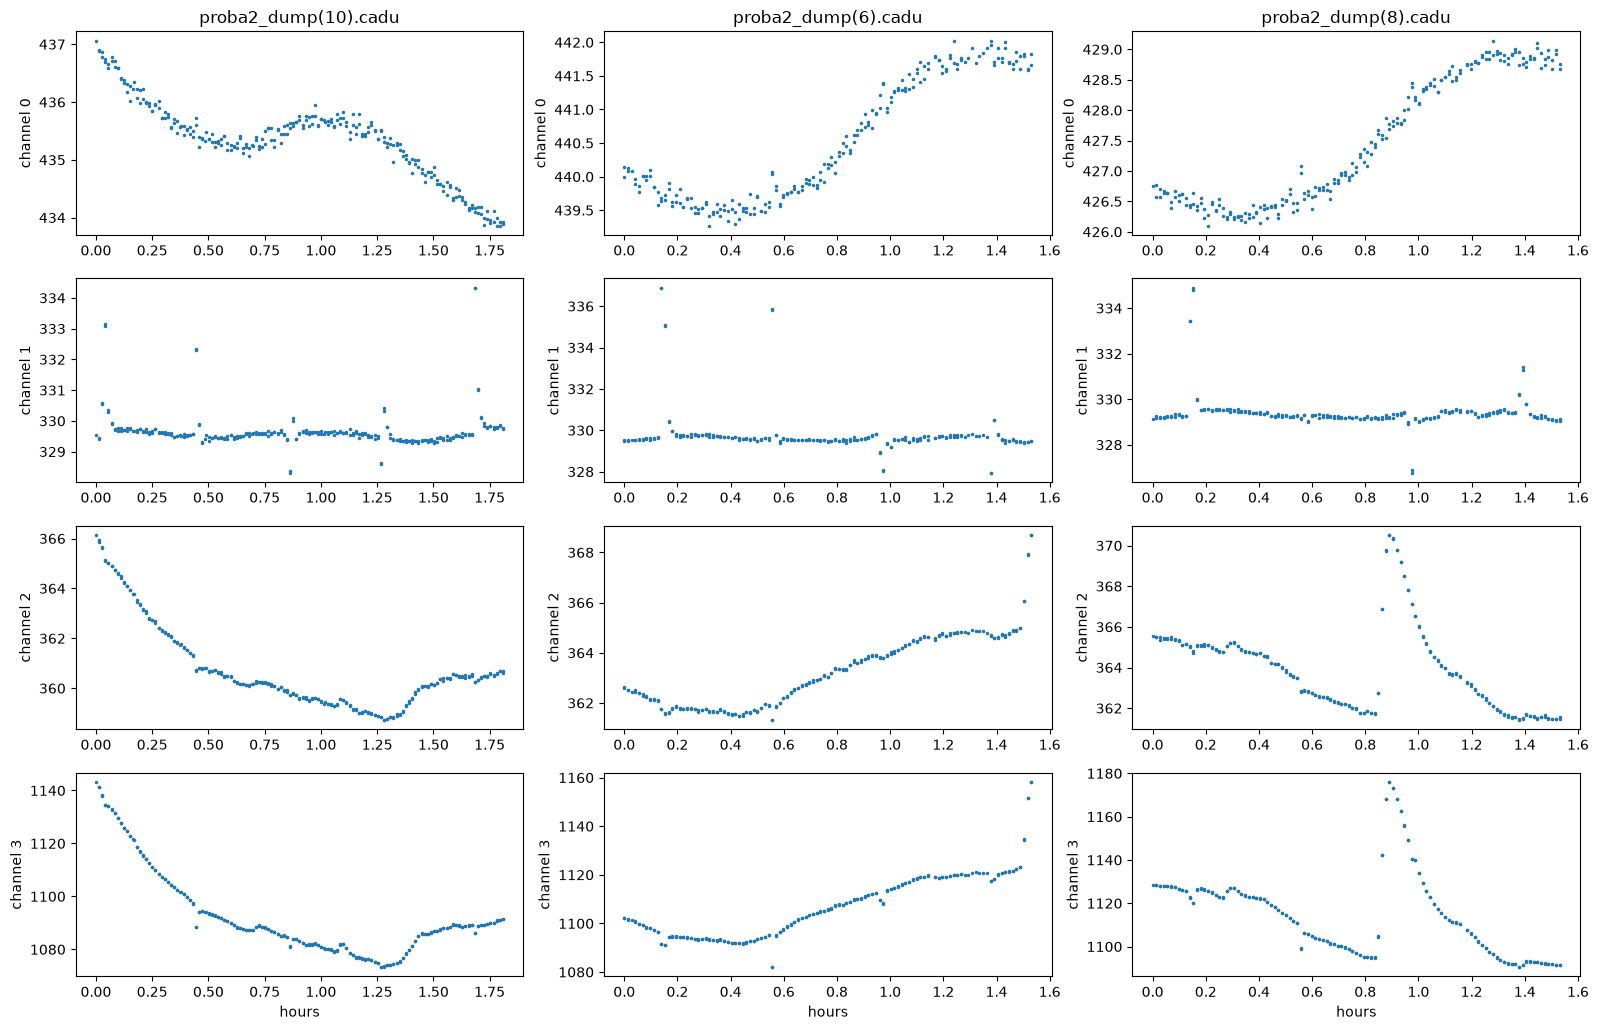

In [15]:
def channels_of(data: bytes) -> np.ndarray:
    """(4, 501) array of the samples of a block."""
    rows = signed24(data[:SAMPLE_SECTION]).reshape(CHANNELS, SAMPLES)
    return rows[:, :1] + np.cumsum(
        np.concatenate([np.zeros((CHANNELS, 1), dtype=np.int64), rows[:, 1:]], axis=1), axis=1
    )


per_file = defaultdict(list)  # file -> (tick, means, stds)
for name, tick, _, data in normal:
    series = channels_of(data)
    per_file[name].append((tick, series.mean(axis=1), series.std(axis=1)))

fig, axes = plt.subplots(CHANNELS, len(per_file), figsize=(16, 2.6 * CHANNELS), squeeze=False)
for column, (name, rows) in enumerate(sorted(per_file.items())):
    ticks = np.array([row[0] for row in rows])
    means = np.array([row[1] for row in rows])
    for channel in range(CHANNELS):
        axes[channel, column].plot((ticks - ticks[0]) / 3600, means[:, channel], ".", markersize=3)
        axes[channel, column].set_ylabel(f"channel {channel}")
    axes[0, column].set_title(name)
    axes[-1, column].set_xlabel("hours")
fig.tight_layout()
plt.show()

channel 0: mean level 426 to 442 (median 435), noise within a packet 1.71
channel 1: mean level 327 to 337 (median 330), noise within a packet 0.76
channel 2: mean level 359 to 371 (median 362), noise within a packet 0.50
channel 3: mean level 1073 to 1176 (median 1100), noise within a packet 2.26


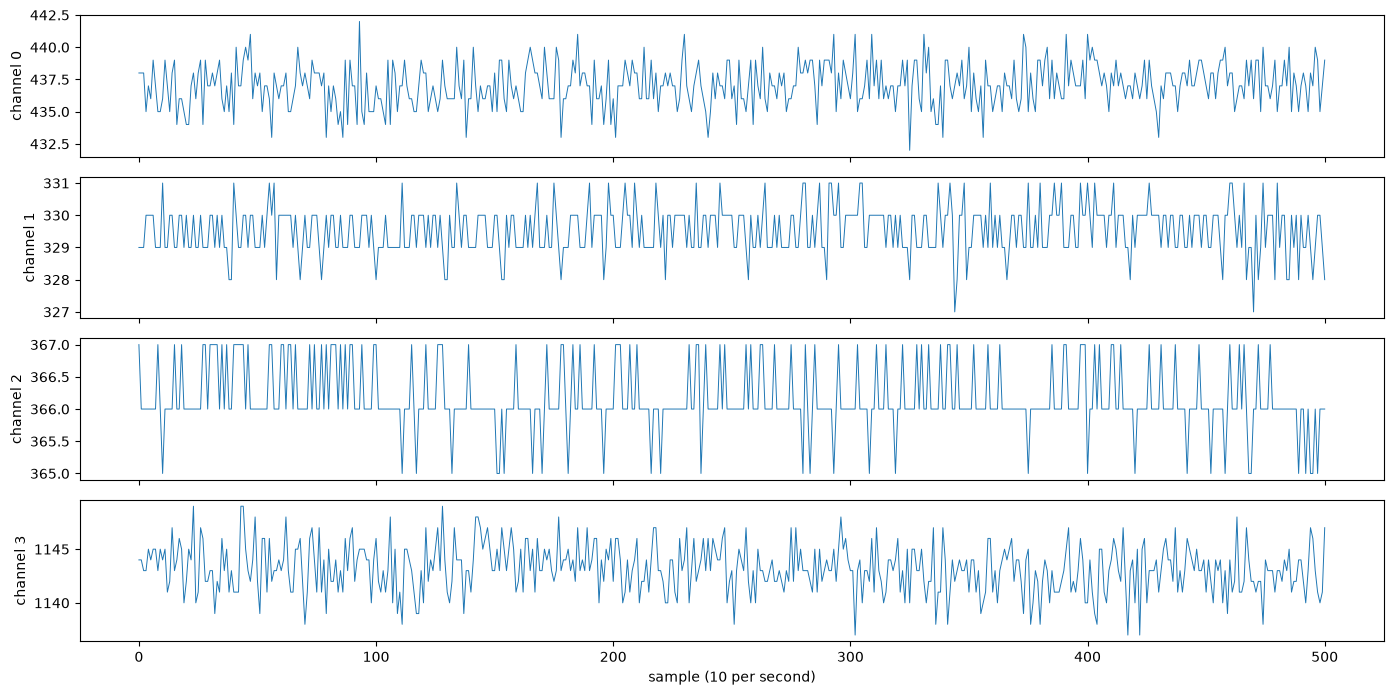

In [16]:
spread = np.array([row[2] for rows in per_file.values() for row in rows])
level = np.array([row[1] for rows in per_file.values() for row in rows])
for channel in range(CHANNELS):
    print(
        f"channel {channel}: mean level {level[:, channel].min():.0f} to {level[:, channel].max():.0f} "
        f"(median {np.median(level[:, channel]):.0f}), noise within a packet {np.median(spread[:, channel]):.2f}"
    )

fig, axes = plt.subplots(CHANNELS, 1, figsize=(14, 7), sharex=True)
for channel, ax in enumerate(axes):
    ax.plot(channels_of(example)[channel], linewidth=0.7)
    ax.set_ylabel(f"channel {channel}")
axes[-1].set_xlabel("sample (10 per second)")
fig.tight_layout()
plt.show()

In [17]:
print("windows covered by the normal packets (GPS time from the APID 18 clock):")
for name, rows in sorted(per_file.items()):
    start, end = rows[0][0], rows[-1][0]
    when = GPS_EPOCH + timedelta(seconds=start + GPS_MINUS_TICK)
    print(f"  {name:22s} {when:%Y-%m-%d %H:%M:%S}  for {(end - start) / 3600:.2f} h, {len(rows)} packets")

windows covered by the normal packets (GPS time from the APID 18 clock):
  proba2_dump(10).cadu   2025-08-14 15:04:06  for 1.81 h, 261 packets
  proba2_dump(6).cadu    2025-08-19 02:16:20  for 1.53 h, 212 packets
  proba2_dump(8).cadu    2025-08-17 02:23:32  for 1.53 h, 219 packets


What the plots show:

* The four channels are **flat**: a level of about 435, 330, 360 and 1100 counts with a noise of 0.5 to 2.3 counts,
  and channels 0, 2 and 3 drift together by a few counts over an hour (in dump 10 a fall, a flat part and a rise
  again), the way an offset that follows a temperature does.
* There is no sign of the Sun in the three windows of 1.5 to 1.8 hours each (about one orbit of 99 minutes each): no eclipse
  steps, no day / night change.
* In dumps 6 and 8 the isolated outliers on all four channels are the 4 packets that are different.

### The eclipse dump

`proba2_dump_aug_12_eclipse.cadu` is a dump from a large partial solar eclipse. It has 40 packets of APID 21, which the
analysis above leaves out. They do not read like the others:

* none passes the CRC, and none decompresses to the end;
* a complete packet is about 3.5 kB instead of 1.6 kB (the data is less compressible, so the differences are bigger),
  which makes it 4 frames long;
* the dump itself is damaged: the frame counters of the virtual channels jump hundreds of times, and only 80 to 90 % of
  its other packets (APID 18, APID 2) pass their CRC, against 99.5 % in the other dumps.

So there is no intact packet. What can be done is to decode every packet up to its first error: the first values and
as many differences as come before it, cut where a difference is not credible (the good data has differences of
10 counts at most). Channel 0 comes first in the block, so it survives most often, and channels 1 to 3 only in the
packets with an error late or none. Times are those of the packet minus 50 s, plus 0.1 s per sample.

18 of 40 packets have a readable start
GPS time of the first one: 2026-08-12 15:44:33+00:00 (offset of the other dumps)
channel 0: 18 packets, 2658 samples
channel 1: 3 packets, 1273 samples
channel 2: 2 packets, 812 samples
channel 3: 1 packets, 93 samples


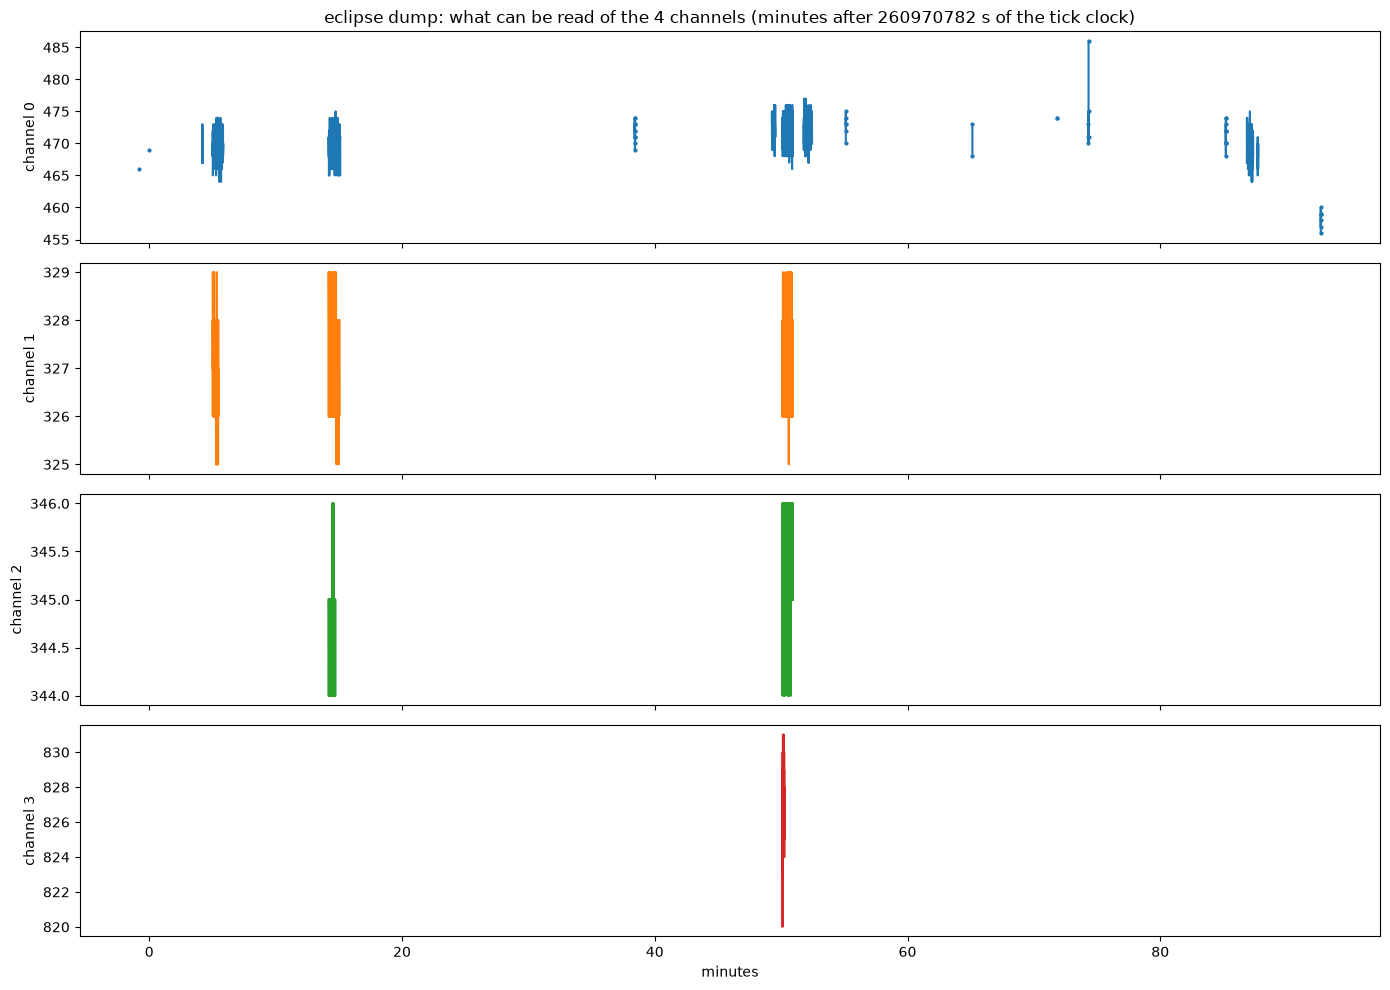

In [18]:
MAX_OFFSET = 1000  # counts away from the median of the first values
MAX_STEP = 100  # counts; a difference above it is an error that the LZW decoder did not notice
SAMPLE_PERIOD = 0.1  # s
PACKET_SPAN = 50  # s of data in a packet, ending about at its tick


def partial_channels(packet: bytes) -> list[np.ndarray]:
    """The samples of each channel that can be read before the first error of the block (a prefix of the channels)."""
    data = uncompress(packet[BLOCK_OFFSET:-CRC_LEN], strict=False)
    numbers = signed24(data[: len(data) // 3 * 3])
    channels = []
    for channel in range(CHANNELS):
        row = numbers[channel * SAMPLES : (channel + 1) * SAMPLES]
        if len(row) == 0:
            break
        steps = row[1:]
        credible = np.abs(steps) <= MAX_STEP
        valid = steps if credible.all() else steps[: np.argmin(credible)]
        channels.append(row[0] + np.concatenate([[0], np.cumsum(valid)]))
        if len(valid) < SAMPLES - 1:
            break  # the error is in this block, so the next ones are lost
    return channels


readable = []  # (tick, channels) of the packets of the eclipse dump with a block that starts like the others
for _, _, packet in eclipse_packets:
    first_counter = int.from_bytes(packet[FIRST_COUNTER_OFFSET : FIRST_COUNTER_OFFSET + 3])
    last_counter = int.from_bytes(packet[LAST_COUNTER_OFFSET : LAST_COUNTER_OFFSET + 3])
    if packet[BLOCK_OFFSET : BLOCK_OFFSET + 3] != b"\x1f\x9d\x8c" or last_counter - first_counter != 1000:
        continue  # the header itself is damaged
    channels = partial_channels(packet)
    if channels:
        readable.append((int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]), channels))
readable = [item for item in readable if item[0] < 2 * np.median([t for t, _ in readable])]  # a tick from a bit error
readable.sort(key=lambda item: item[0])
# a damaged header or a bit error in the first value gives a level that is far off: keep the channels up to there
reference = [
    np.median([channels[channel][0] for _, channels in readable if len(channels) > channel])
    for channel in range(CHANNELS)
]


def plausible_prefix(channels: list[np.ndarray]) -> list[np.ndarray]:
    kept = []
    for channel, row in enumerate(channels):
        if abs(row[0] - reference[channel]) >= MAX_OFFSET:
            break
        kept.append(row)
    return kept


readable = [(tick, plausible_prefix(channels)) for tick, channels in readable]
readable = [(tick, channels) for tick, channels in readable if channels]

start = readable[0][0]
print(f"{len(readable)} of {len(eclipse_packets)} packets have a readable start")
print(
    "GPS time of the first one:", GPS_EPOCH + timedelta(seconds=start + GPS_MINUS_TICK), "(offset of the other dumps)"
)
for channel in range(CHANNELS):
    counts = [len(channels[channel]) for _, channels in readable if len(channels) > channel]
    print(f"channel {channel}: {len(counts)} packets, {sum(counts)} samples")

fig, axes = plt.subplots(CHANNELS, 1, figsize=(14, 10), sharex=True)
for channel, ax in enumerate(axes):
    for tick, channels in readable:
        if len(channels) > channel:
            samples = channels[channel]
            seconds = tick - PACKET_SPAN - start + SAMPLE_PERIOD * np.arange(len(samples))
            ax.plot(seconds / 60, samples, ".-" if len(samples) < 20 else "-", markersize=4, color=f"C{channel}")
    ax.set_ylabel(f"channel {channel}")
axes[0].set_title(f"eclipse dump: what can be read of the 4 channels (minutes after {start} s of the tick clock)")
axes[-1].set_xlabel("minutes")
fig.tight_layout()
plt.show()

What the eclipse dump gives:

* Only 18 of the 40 packets have a start that can be read, and of those only the first channel comes out for most
  (2 658 samples); channel 1 from 3 packets, channel 2 from 2, channel 3 from 1. In all, about a fifth of the 93 minutes
  has data for channel 0 and a few minutes for the others.
* What is readable is **flat**: channel 0 stays at 466 to 474 counts (noise of a few counts) for the first 90 minutes,
  channel 1 at 326, channel 2 at 345, channel 3 at 829. No dip and no step at the times that were recovered. The one
  exception is the very last packet (minute 92, 7 samples), where channel 0 is at 456 to 460, about 12 counts lower. That
  is a change of 2.5 %, one packet only, and the 2025 dumps drift by several counts over an hour too, so it proves
  nothing.
* The levels are not those of the 2025 dumps (435, 330, 362, 1 100): a year later channel 0 is 8 % higher and
  channel 3 25 % lower, so the offsets drift over time.
* The dump is from 2026-08-12 (GPS clock of the other dumps: the first packet is at 15:44:33), the date of the eclipse
  in the file name, which supports the tick to date conversion.

So in the part of the eclipse that was recovered, APID 21 does not react to the Moon covering the Sun. The recovered times
cover only a fifth of the window, so a short dip could fall between them, but a solar channel would not stay flat to a few
counts for 90 minutes (a 2.5 % change is nothing like an eclipse of the Sun). Together with the flat 2025 data this points to dark or offset values rather than irradiance.
The same dump has 375 packets of APID 20 (SWAP images), which would show the eclipse directly, and no APID 22 at all.

## 7. LYRA?

For LYRA:

* 4 channels (LYRA has 4 per unit) in one block with a 20 Hz sample counter (LYRA's nominal cadence), samples every
  2 counts (10 Hz per channel);
* the data is compressed on board (the description says the raw output "must be unpacked, sorted and decompressed")
  and comes with a flag word per sample (LYRA's raw data has flagged entries, for example after a change of the
  integration time) and with the time marks that tie the sample counter to the clock;
* packets of exactly 1002 counts every 50 s, with the sample counter continuing from packet to packet.

Against, or not yet explained:

* the channels do not show any solar signal in the 5 hours covered, only flat levels of a few hundred to a thousand
  counts. LYRA, pointed at the Sun, would show large irradiance counts that change at every eclipse and flare. These
  could be dark levels (the unit not exposed, or an unused unit), or a different instrument with the same
  electronics;
* the flag words are all 2, which tells nothing without the ICD.

To decide: compare the levels and the slow drifts with a LYRA raw (Level 1) file of the windows printed above. If APID
21 is LYRA, the levels will match a unit's dark / offset values for these days, and its other units or channels
would be in packets of other APIDs (see the 4 packets that are different, and APIDs 14, 8 and 11).

*Done in section 9: it is LYRA, and the levels are real counts, not dark values.*


## 8. Cross-correlation with LYRA (sunpy)

The eclipse dump is the one place where a solar signal is known to exist: LYRA's own record of 2026-08-12 shows the
Moon covering the Sun. Download that day's calibrated LYRA data (level 2, 20 Hz) with sunpy, and compare it with the
channel 0 samples recovered above. Only channel 0 is used: it is the only one with a useful amount of samples.

In [19]:
LYRA_DIR = Path("lyra")
LYRA_DAY = ("2026-08-12", "2026-08-12 23:59")

found = Fido.search(a.Time(*LYRA_DAY), a.Instrument.lyra, a.Level(2))
files = Fido.fetch(found, path=str(LYRA_DIR / "{file}"), progress=False)  # a file that is already there is kept
# the FITS columns are big-endian, which the reductions of pandas refuse
lyra = TimeSeries(files).to_dataframe().astype("float64")
print(f"{len(lyra)} LYRA samples, {lyra.index[0]} to {lyra.index[-1]}")
print(lyra.columns.tolist())

1723101 LYRA samples, 2026-08-12 00:00:00.064000 to 2026-08-12 23:59:59.995000
['CHANNEL1', 'CHANNEL2', 'CHANNEL3', 'CHANNEL4']


LYRA channels 1 to 4 are Lyman alpha, Herzberg, aluminium and zirconium. The eclipse should show most in zirconium (the
hot corona), less in aluminium, and not at all in the two UV channels, which come from the whole disc.

Put both on one time axis, the seconds since the GPS epoch. The times of the APID 21 samples are those of the
notebook (packet tick minus 50 s plus 0.1 s per sample, then the GPS offset from APID 18). That clock is GPS time, which
runs about 18 s ahead of the UTC of LYRA, and the packet times themselves are only good to a few seconds; both are
far below the minutes the eclipse takes, and below the 10 s bins used next, so no correction is made.

In [20]:
GPS_START = pd.Timestamp(GPS_EPOCH.replace(tzinfo=None))
lyra_seconds = (lyra.index - GPS_START).total_seconds().to_numpy()
apid_seconds = np.concatenate(
    [tick - PACKET_SPAN + GPS_MINUS_TICK + SAMPLE_PERIOD * np.arange(len(channels[0])) for tick, channels in readable]
)
apid_counts = np.concatenate([channels[0] for _, channels in readable]).astype(float)
order = np.argsort(apid_seconds)  # a few packets overlap in time
apid_seconds, apid_counts = apid_seconds[order], apid_counts[order]

BIN = 10  # s
first_bin = int(lyra_seconds[0] // BIN)
bin_count = int((lyra_seconds[-1] - lyra_seconds[0]) // BIN) + 1


def binned(seconds: np.ndarray, values: np.ndarray) -> np.ndarray:
    """Mean of the values in each bin of BIN seconds of the LYRA day, NaN where there is none."""
    index = (seconds // BIN).astype(int) - first_bin
    inside = (index >= 0) & (index < bin_count)
    totals = np.bincount(index[inside], values[inside], bin_count)
    counts = np.bincount(index[inside], minlength=bin_count)
    return np.divide(totals, counts, out=np.full(bin_count, np.nan), where=counts > 0)


lyra_binned = {name: binned(lyra_seconds, lyra[name].to_numpy()) for name in lyra.columns}
apid_binned = binned(apid_seconds, apid_counts)
has_apid = np.flatnonzero(~np.isnan(apid_binned))
print(f"{len(has_apid)} bins of {BIN} s with APID 21 samples, {len(has_apid) * BIN / 60:.1f} minutes in all")

41 bins of 10 s with APID 21 samples, 6.8 minutes in all


Correlate the binned APID 21 channel 0 with each LYRA channel, shifting LYRA by up to 3 hours either way. At lag 0
the two clocks agree. The other lags are the null: the same amount of LYRA signal, with no physical link. If channel 0
follows the Sun, r at lag 0 should be clearly above the rest.

In [21]:
MAX_LAG = 3 * 3600 // BIN  # bins
lags = np.arange(-MAX_LAG, MAX_LAG + 1)
correlation = {}
for name, series in lyra_binned.items():
    values = []
    for lag in lags:
        shifted = has_apid + lag
        valid = (shifted >= 0) & (shifted < bin_count)
        x, y = series[shifted[valid]], apid_binned[has_apid[valid]]
        good = ~np.isnan(x)
        values.append(np.corrcoef(x[good], y[good])[0, 1] if good.sum() > 30 else np.nan)
    correlation[name] = np.array(values)
    r = correlation[name]
    zero = r[MAX_LAG]
    print(
        f"{name}: r(0) = {zero:+.2f}, rank {int((r > zero).sum()) + 1} of {int((~np.isnan(r)).sum())} lags, "
        f"spread of the other lags {np.nanstd(r):.2f}, largest {np.nanmax(r):+.2f} at {lags[np.nanargmax(r)] * BIN} s"
    )

CHANNEL1: r(0) = +0.47, rank 150 of 2161 lags, spread of the other lags 0.34, largest +0.93 at 7290 s


CHANNEL2: r(0) = +0.66, rank 40 of 2161 lags, spread of the other lags 0.28, largest +0.82 at -7360 s


CHANNEL3: r(0) = +0.78, rank 48 of 2161 lags, spread of the other lags 0.40, largest +0.89 at 6710 s


CHANNEL4: r(0) = +0.78, rank 56 of 2161 lags, spread of the other lags 0.40, largest +0.90 at 6710 s


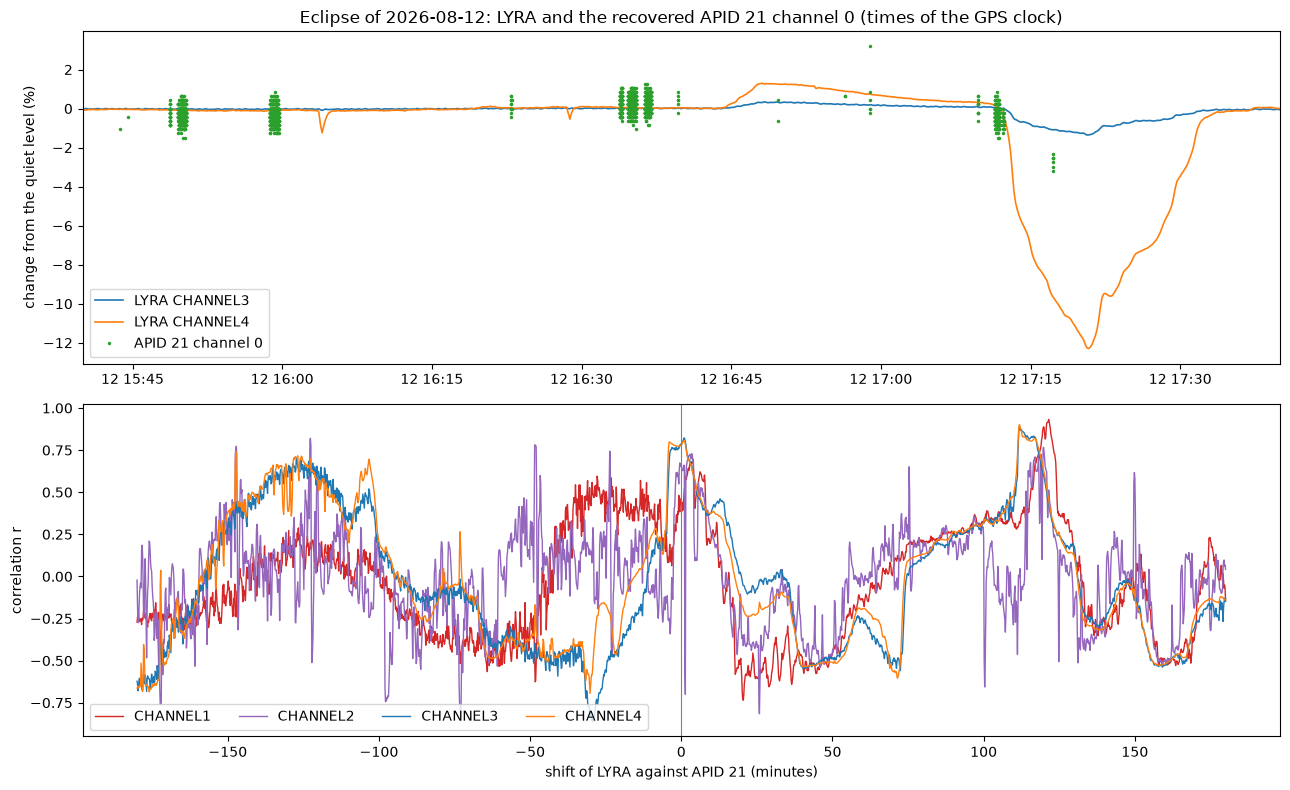

In [22]:
WINDOW = ("2026-08-12 15:40", "2026-08-12 17:40")
baseline = lyra.loc["2026-08-12 15:40":"2026-08-12 17:00"].median()
apid_baseline = np.median(apid_counts[apid_seconds < apid_seconds[-1] - 600])  # everything before the last minutes
apid_time = GPS_START + pd.to_timedelta(apid_seconds, unit="s")

fig, (series_ax, lag_ax) = plt.subplots(2, 1, figsize=(13, 8))
for name, color in (("CHANNEL3", "C0"), ("CHANNEL4", "C1")):
    change = (lyra[name].resample("10s").mean() / baseline[name] - 1) * 100
    series_ax.plot(change.loc[WINDOW[0] : WINDOW[1]], color=color, linewidth=1.2, label=f"LYRA {name}")
series_ax.plot(
    apid_time, (apid_counts / apid_baseline - 1) * 100, ".", color="C2", markersize=3, label="APID 21 channel 0"
)
series_ax.set_xlim(pd.Timestamp(WINDOW[0]), pd.Timestamp(WINDOW[1]))
series_ax.set_ylabel("change from the quiet level (%)")
series_ax.set_title("Eclipse of 2026-08-12: LYRA and the recovered APID 21 channel 0 (times of the GPS clock)")
series_ax.legend(loc="lower left")

for name, color in zip(lyra.columns, ("C3", "C4", "C0", "C1"), strict=True):
    lag_ax.plot(lags * BIN / 60, correlation[name], color=color, linewidth=1.0, label=name)
lag_ax.axvline(0, color="gray", linewidth=0.8)
lag_ax.set_xlabel("shift of LYRA against APID 21 (minutes)")
lag_ax.set_ylabel("correlation r")
lag_ax.legend(loc="lower left", ncol=4)
fig.tight_layout()
plt.show()

In [23]:
before = apid_counts[(apid_seconds > apid_seconds[-1] - 700) & (apid_seconds < apid_seconds[-1] - 60)]
dip = apid_counts[apid_seconds >= apid_seconds[-1] - 1]
dip_time = GPS_START + pd.Timedelta(seconds=float(apid_seconds[-1]))
dip_lyra = lyra.loc[dip_time - pd.Timedelta("30s") : dip_time + pd.Timedelta("30s")].mean()
print(
    f"APID 21 channel 0 in the 10 minutes before the last packet: {before.mean():.1f} counts ({len(before)} samples)"
)
print(
    f"in the last packet ({dip_time:%H:%M:%S}, {len(dip)} samples): {dip.mean():.1f} counts, "
    f"{dip.mean() - before.mean():+.1f} = {(dip.mean() / before.mean() - 1) * 100:+.1f} %"
)
print("LYRA change over the same minute against the quiet level (%):")
print(((dip_lyra / baseline - 1) * 100).round(2).to_string())

APID 21 channel 0 in the 10 minutes before the last packet: 469.2 counts (339 samples)
in the last packet (17:17:15, 7 samples): 458.3 counts, -10.9 = -2.3 %
LYRA change over the same minute against the quiet level (%):
CHANNEL1   -0.01
CHANNEL2   -0.01
CHANNEL3   -1.07
CHANNEL4   -9.53


What the comparison gives:

* LYRA sees the eclipse clearly: from about 17:12 zirconium (channel 4) falls by 12 % at about 17:21 and recovers by 17:35,
  aluminium (channel 3) falls by 1.3 %, and the two UV channels do not move (0.03 %).
* The recovered APID 21 channel 0 is flat (within +-1 %) at all the times before the eclipse, and the last packet, 17:17:15, is
  at the start of it: 458.3 counts against 469.2 before, **-2.3 %**, where LYRA is at -1.1 % (aluminium) and -9.5 % (zirconium) at that
  minute. The sign and the time are right, and the size is between the two LYRA channels, but it is one fragment of 7 samples (0.7 s).
* The cross-correlation is positive for all four LYRA channels at lag 0 (+0.78 for the aluminium and zirconium channels, +0.66 for
  Herzberg, +0.47 for Lyman alpha), but it is **not significant**: of 2 161 lags, 40 to 150 are higher, and the other lags have a spread
  of 0.3 to 0.4, because the 41 bins (6.8 minutes of channel 0 in all) are in a few clusters and the correlation is carried by
  the one cluster that is in the dip. The peaks at +-2 hours are just as high, so this test cannot tell the eclipse from chance.
* The pre-eclipse rise of LYRA channels 3 and 4 around 16:45 to 17:00 (+0.3 % and +1.3 %) is matched by a few channel 0 samples
  at 16:56 to 16:58 (+1 % and a single outlier at +3 %), which is also what a solar channel would do. It is two short fragments, though.

So the dip is where and how LYRA says the eclipse starts, and no other part of the recovered data deviates by more than
1 %, but a fragment of 7 samples is not a correlation. It is a lead for APID 21 being (a mix of) LYRA channels, not a proof. What
would decide it: more of the eclipse (the 22 packets of the dump with an unreadable start, the other 3 channels, and above all
the 17:12 to 17:35 stretch, from which only this one fragment is known), or another eclipse or flare dump.


## 9. LYRA level 1 (raw) against the whole of dump (10)

The eclipse dump has too little data to settle anything, but dump (10) has 261 intact packets with all four channels over
1.8 hours, and a distinctive shape (a fall, a flat part, a rise). LYRA level 1 is the raw output: the data of the same day
before the calibration, in kHz. It is not served through `Fido`, but the files are in the `eng` directory of the same
server (the `std` file is the standard 20 Hz data, 70 MB).

The levels of the APID 21 channels, about 435, 330, 360 and 1100 counts, are about 50 times the levels in kHz of LYRA
channels 1 to 4 (8.9, 6.6, 7.4 and 24 kHz): a count in 50 ms, the period of the 20 Hz sample counter, would be exactly
that. So the test is a physical one with no free parameter: APID 21 channel *n* against 50 times LYRA level 1 channel
*n* + 1, in kHz.

In [24]:
LEVEL1_URL = "https://proba2.sidc.be/lyra/data/eng/{day:%Y/%m/%d}/lyra_{day:%Y%m%d}-000000_lev1_std.fits"
LEVEL1_DUMP = "proba2_dump(10).cadu"
COUNTS_PER_KHZ = 50  # a count in 50 ms: a rate of 1 kHz gives 50 counts in a sample of 50 ms

dump_day = datetime(2025, 8, 14, tzinfo=UTC)  # the day of dump (10): 2025-08-14 15:04, from section 6
level1_path = LYRA_DIR / f"lyra_{dump_day:%Y%m%d}-000000_lev1_std.fits"
if not level1_path.exists():
    LYRA_DIR.mkdir(exist_ok=True)
    urlretrieve(LEVEL1_URL.format(day=dump_day), level1_path)

with fits.open(level1_path) as hdus:
    table = hdus[1].data
    level1_seconds = np.asarray(table["TIME"], dtype=float)  # seconds of the UTC day
    level1_khz = np.array([np.asarray(table[f"CHANNEL{n}"], dtype=float) for n in range(1, 5)])
print(f"{level1_khz.shape[1]} level 1 samples, {np.median(np.diff(level1_seconds)) * 1000:.0f} ms apart")
print("mean level (kHz):", level1_khz.mean(axis=1).round(2))

1724006 level 1 samples, 50 ms apart
mean level (kHz): [ 9.54  6.57  7.33 23.  ]


Now all the samples of dump (10), 4 channels. The time of each is not the packet's tick minus 50 s any more but the one given by
the time marks: the mark gives the clock at a counter value, and a sample is 2 counter units (0.1 s) after the previous
one. The clock is the GPS one of section 8, so seconds since the GPS epoch are turned into seconds of the day of the LYRA
file.

In [25]:
day_start = (dump_day - GPS_EPOCH).total_seconds()  # the GPS epoch seconds of the start of the LYRA day
sample_times, sample_counts = [], []
for name, _, packet, data in normal:
    if name != LEVEL1_DUMP:
        continue
    mark_ticks, mark_fractions, mark_counters = parse_tail(data)
    first_counter = int.from_bytes(packet[FIRST_COUNTER_OFFSET : FIRST_COUNTER_OFFSET + 3])
    counters = first_counter + 2 * np.arange(SAMPLES)
    sample_times.append(
        mark_ticks[0] + mark_fractions[0] + (counters - mark_counters[0]) / 20 + GPS_MINUS_TICK - day_start
    )
    sample_counts.append(channels_of(data))
times = np.concatenate(sample_times)
counts = np.concatenate(sample_counts, axis=1).astype(float)
print(
    f"{len(times)} samples per channel in {len(sample_times)} packets, "
    f"from {times[0] / 3600:.3f} to {times[-1] / 3600:.3f} h"
)

130761 samples per channel in 261 packets, from 15.054 to 16.877 h


First the plain correlation and the slope of APID 21 against the level 1 kHz at lag 0, interpolating LYRA to the sample times.

In [26]:
for channel in range(CHANNELS):
    khz = np.interp(times, level1_seconds, level1_khz[channel])
    slope, offset = np.polyfit(khz, counts[channel], 1)
    print(
        f"channel {channel} ~ LYRA {channel + 1}: r = {np.corrcoef(khz, counts[channel])[0, 1]:.3f}, "
        f"slope {slope:.1f} counts per kHz, offset {offset:+.1f}"
    )

channel 0 ~ LYRA 1: r = 0.158, slope 9.6 counts per kHz, offset +351.7
channel 1 ~ LYRA 2: r = 0.173, slope 9.8 counts per kHz, offset +265.2


channel 2 ~ LYRA 3: r = 0.932, slope 48.2 counts per kHz, offset +13.2
channel 3 ~ LYRA 4: r = 0.980, slope 50.0 counts per kHz, offset +0.2


The zirconium and aluminium channels (3 and 2) are the ones that vary (the level moves by tens of counts), and for them
r is 0.98 and 0.93 with a slope of 50. The other two are flat to a few counts, so r tells little there; they are judged by
their mean below.

The clock is also not exact. Scan the time shift of APID 21 against LYRA: broadly with the interpolated level 1 (the
residual of APID 21 minus 50 times level 1 is smallest at the right shift), then finely with the nearest level 1
sample, which is sharp if the two are really the same 20 Hz series.

broad minimum at +21.00 s, sharp one at +21.11 s (residual 1.60 counts)


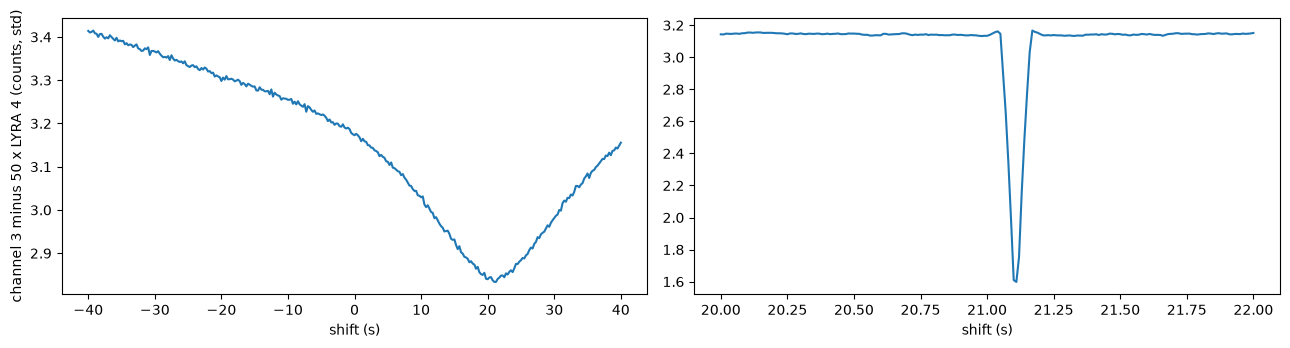


with that shift, APID 21 minus 50 x level 1 (nearest sample):
channel 0: mean -0.09, std 1.22 counts (the channel itself: mean 435.4, std 1.84)
channel 1: mean -0.07, std 0.64 counts (the channel itself: mean 329.7, std 1.17)
channel 2: mean -0.08, std 0.39 counts (the channel itself: mean 360.7, std 1.74)
channel 3: mean -0.23, std 1.60 counts (the channel itself: mean 1092.4, std 16.04)


In [27]:
def nearest(shift: float, channel: int) -> np.ndarray:
    """50 times the level 1 sample nearest to each APID 21 sample, with LYRA shifted by `shift` seconds."""
    wanted = times - shift
    index = np.clip(np.searchsorted(level1_seconds, wanted), 1, len(level1_seconds) - 1)
    index -= np.abs(level1_seconds[index - 1] - wanted) < np.abs(level1_seconds[index] - wanted)
    return COUNTS_PER_KHZ * level1_khz[channel][index]


coarse = np.arange(-40, 40.01, 0.25)
spread = [
    (counts[3] - COUNTS_PER_KHZ * np.interp(times - shift, level1_seconds, level1_khz[3])).std() for shift in coarse
]
rough = coarse[np.argmin(spread)]
fine = np.arange(rough - 1, rough + 1.001, 0.01)
spread_fine = [(counts[3] - nearest(shift, 3)).std() for shift in fine]
SHIFT = float(fine[np.argmin(spread_fine)])
print(f"broad minimum at {rough:+.2f} s, sharp one at {SHIFT:+.2f} s (residual {min(spread_fine):.2f} counts)")

fig, (broad_ax, sharp_ax) = plt.subplots(1, 2, figsize=(13, 3.5))
broad_ax.plot(coarse, spread)
broad_ax.set_xlabel("shift (s)")
broad_ax.set_ylabel("channel 3 minus 50 x LYRA 4 (counts, std)")
sharp_ax.plot(fine, spread_fine)
sharp_ax.set_xlabel("shift (s)")
fig.tight_layout()
plt.show()

print()
print("with that shift, APID 21 minus 50 x level 1 (nearest sample):")
for channel in range(CHANNELS):
    difference = counts[channel] - nearest(SHIFT, channel)
    print(
        f"channel {channel}: mean {difference.mean():+.2f}, std {difference.std():.2f} counts "
        f"(the channel itself: mean {counts[channel].mean():.1f}, std {counts[channel].std():.2f})"
    )

The shift is found, and the same for all channels: the broad minimum is about 21 s, and the sharp one at 21.11 s. The 18 s
of the leap seconds between GPS time and UTC are most of it, the 3 s that remain are the unknown of the clock (the offset was derived from APID 18). Section 10 finds other shifts in the other dumps, so the 3 s is a drift, not a constant. The difference between APID 21 and 50 times level 1 has a mean of -0.1 counts in all
4 channels, with no fitted scale or offset, and the standard deviation of 0.4 to 1.6 counts is below the variation of
each channel itself (1.2 against 1.8, 0.64 against 1.2, 0.39 against 1.7, 1.6 against 16). The samples are not the same
numbers though (level 1 values are 50 times kHz = whole counts + 0.24, and the pairs differ by more than 1.5 counts in 0.5 to 16 % of
the samples), so APID 21 is another readout of the same signal, not a copy of this file.

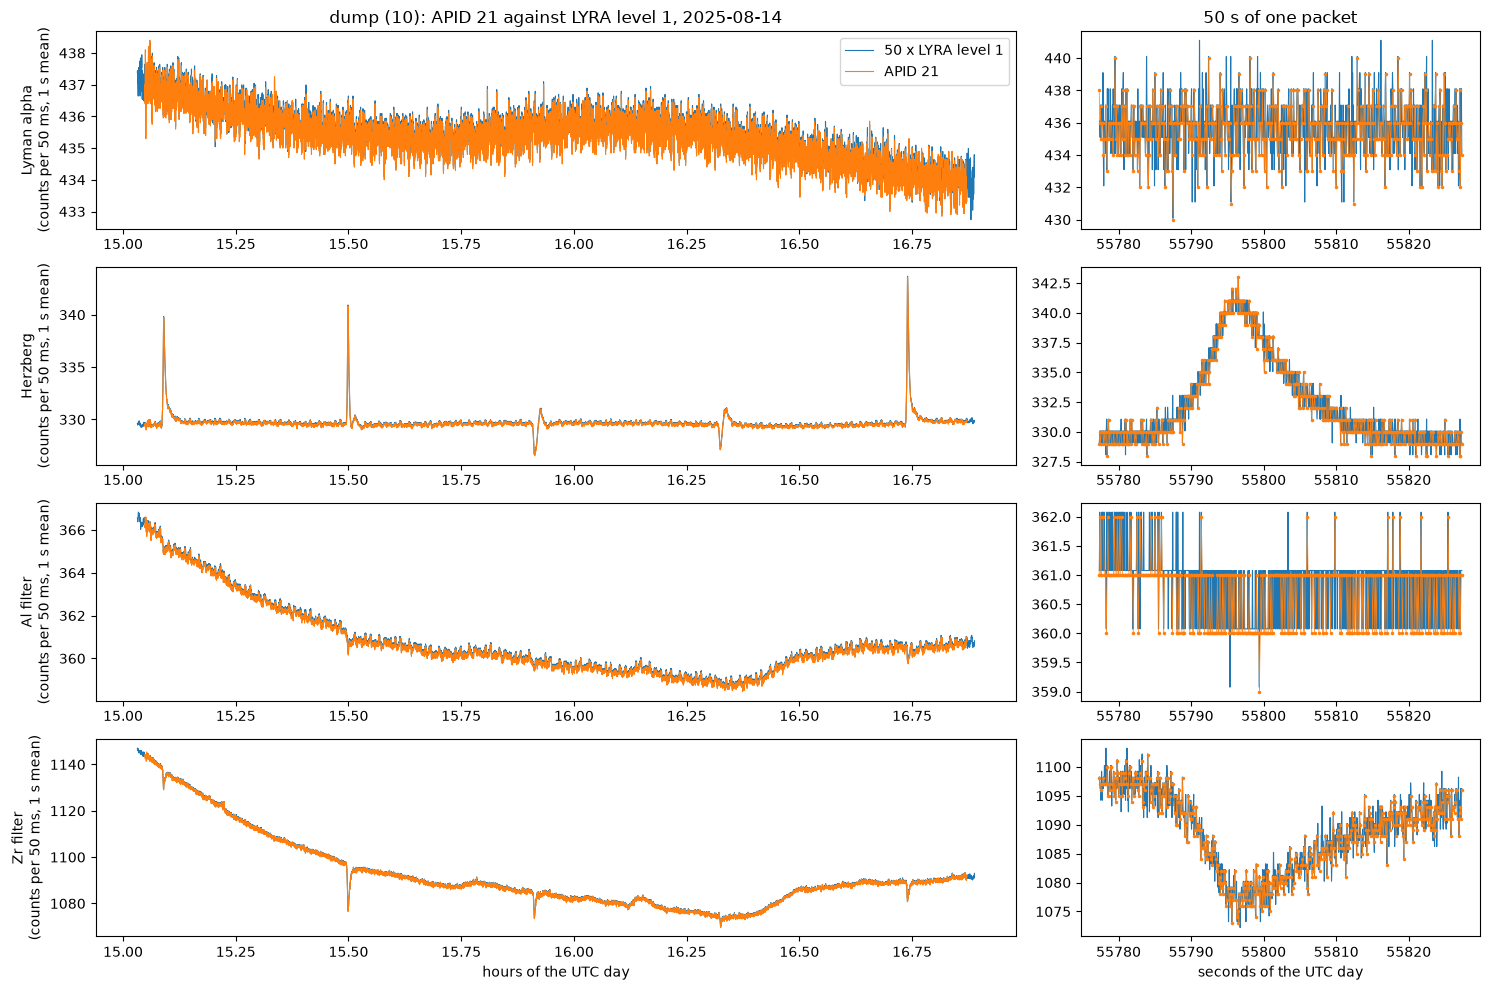

In [28]:
shifted_times = times - SHIFT
channel_names = ["Lyman alpha", "Herzberg", "Al filter", "Zr filter"]
zoom_packet = int(np.argmax([block[3].std() for block in sample_counts]))  # the packet where Zr varies the most
zoom = slice(zoom_packet * SAMPLES, (zoom_packet + 1) * SAMPLES)

fig, axes = plt.subplots(CHANNELS, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [3, 1.3]})
window = (level1_seconds >= shifted_times[0] - 60) & (level1_seconds <= shifted_times[-1] + 60)


def per_second(seconds: np.ndarray, values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Mean of the values over each whole second (the left panels would be a solid band at 20 Hz)."""
    index = np.floor(seconds).astype(int)
    index -= index.min()
    totals, number = np.bincount(index, values), np.bincount(index)
    kept = number > 0
    return np.flatnonzero(kept) + np.floor(seconds.min()) + 0.5, totals[kept] / number[kept]


for channel in range(CHANNELS):
    whole, close = axes[channel]
    level1_mean = per_second(level1_seconds[window], COUNTS_PER_KHZ * level1_khz[channel][window])
    apid_mean = per_second(shifted_times, counts[channel])
    whole.plot(level1_mean[0] / 3600, level1_mean[1], linewidth=0.8, label="50 x LYRA level 1")
    whole.plot(apid_mean[0] / 3600, apid_mean[1], linewidth=0.8, label="APID 21")
    whole.set_ylabel(f"{channel_names[channel]}\n(counts per 50 ms, 1 s mean)")
    in_zoom = (level1_seconds >= shifted_times[zoom][0]) & (level1_seconds <= shifted_times[zoom][-1])
    close.plot(level1_seconds[in_zoom], COUNTS_PER_KHZ * level1_khz[channel][in_zoom], linewidth=0.8)
    close.plot(shifted_times[zoom], counts[channel][zoom], ".-", markersize=3, linewidth=0.5)
axes[0, 0].set_title("dump (10): APID 21 against LYRA level 1, 2025-08-14")
axes[0, 0].legend(loc="upper right")
axes[0, 1].set_title("50 s of one packet")
axes[-1, 0].set_xlabel("hours of the UTC day")
axes[-1, 1].set_xlabel("seconds of the UTC day")
fig.tight_layout()
plt.show()

What the figure shows, for all four channels over 1.8 hours:

* **Every feature of APID 21 is in LYRA level 1, at the same time and with the same size**, with no scale fitted: the slow fall of
  Lyman alpha (437 to 434 counts), the stepped fall of the aluminium channel (367 to 359), the fall and partial recovery of the zirconium channel (1145 to 1070 to
  1090), its short dips at 15.50 h and 15.92 h, and the three spikes of the Herzberg channel (15.09 h, 15.50 h and 16.74 h, up to
  +15 counts), of which the right panel shows one in detail. The "flat levels" and "drift like a temperature offset" of section 6
  are the real LYRA signal, not dark values: LYRA's channels change by a few counts only in this window (no flare or eclipse in it).
* The scale is the one of a **count in 50 ms (50 counts per kHz)**, so APID 21 is LYRA's raw counts per sample of the 20 Hz
  cadence, kept every second one (10 per second), one per channel in the order of LYRA channels 1 to 4.
* The clock of the APID 21 samples is 21.11 s ahead of the UTC of the LYRA file (18 s of leap seconds and 3.11 s that are
  the clock error of the offset from APID 18). That is also small enough for section 8 (minutes and 10 s bins) not to be affected.
* The samples are not an exact copy of the level 1 `std` file (residual 0.4 to 1.6 counts rms, within 1.5 counts in 99.5 % of the samples of
  the aluminium channel, 84 % for zirconium). Possibly it is another unit (LYRA has three, and the level 1 directory has
  `bst`, `bca`, `bre`, `cal`, `met` and `rej` files as well), or the on-board sample is taken at another instant of the 50 ms.
  Not tested.


## 10. The same test on dumps 6 and 8

One dump could be a coincidence of a smooth trend, so repeat the test of section 9 on the other two dumps with
APID 21, from other days (2025-08-17 and 2025-08-19), with the scale of 50 counts per kHz fixed and nothing taken from dump (10):
the shift of the clock is found again for each dump. The steps of section 9 are put in a function.

In [29]:
DUMP_DAYS = {  # dump -> day of the UTC date of the GPS dates of section 6
    "proba2_dump(10).cadu": datetime(2025, 8, 14, tzinfo=UTC),
    "proba2_dump(8).cadu": datetime(2025, 8, 17, tzinfo=UTC),
    "proba2_dump(6).cadu": datetime(2025, 8, 19, tzinfo=UTC),
}


def load_level1(day: datetime) -> tuple[np.ndarray, np.ndarray]:
    """Seconds of the UTC day and the 4 channels in kHz of the level 1 `std` file of a day (downloaded if needed)."""
    path = LYRA_DIR / f"lyra_{day:%Y%m%d}-000000_lev1_std.fits"
    if not path.exists():
        LYRA_DIR.mkdir(exist_ok=True)
        urlretrieve(LEVEL1_URL.format(day=day), path)
    with fits.open(path) as hdus:
        table = hdus[1].data
        seconds = np.asarray(table["TIME"], dtype=float)
        khz = np.array([np.asarray(table[f"CHANNEL{n}"], dtype=float) for n in range(1, 5)])
    return seconds, khz


def dump_samples(dump: str, day: datetime) -> tuple[np.ndarray, np.ndarray]:
    """Times (seconds of the UTC day, GPS clock) and counts (4, n) of all the normal packets of a dump."""
    day_start = (day - GPS_EPOCH).total_seconds()
    sample_times, sample_counts = [], []
    for name, _, packet, data in normal:
        if name != dump:
            continue
        mark_ticks, mark_fractions, mark_counters = parse_tail(data)
        first_counter = int.from_bytes(packet[FIRST_COUNTER_OFFSET : FIRST_COUNTER_OFFSET + 3])
        counters = first_counter + 2 * np.arange(SAMPLES)
        sample_times.append(
            mark_ticks[0] + mark_fractions[0] + (counters - mark_counters[0]) / 20 + GPS_MINUS_TICK - day_start
        )
        sample_counts.append(channels_of(data))
    return np.concatenate(sample_times), np.concatenate(sample_counts, axis=1).astype(float)


def nearest_level1(seconds: np.ndarray, khz: np.ndarray, wanted: np.ndarray, channel: int) -> np.ndarray:
    """50 times the level 1 sample nearest to each wanted time."""
    index = np.clip(np.searchsorted(seconds, wanted), 1, len(seconds) - 1)
    index -= np.abs(seconds[index - 1] - wanted) < np.abs(seconds[index] - wanted)
    return COUNTS_PER_KHZ * khz[channel][index]


def find_shift(seconds: np.ndarray, khz: np.ndarray, times: np.ndarray, counts: np.ndarray) -> float:
    """Shift of the APID 21 clock against LYRA: broad scan with the interpolated level 1, then the sharp one."""
    coarse = np.arange(-40, 40.01, 0.25)
    spread = [(counts[3] - COUNTS_PER_KHZ * np.interp(times - shift, seconds, khz[3])).std() for shift in coarse]
    rough = coarse[np.argmin(spread)]
    fine = np.arange(rough - 1, rough + 1.001, 0.01)
    spread_fine = [(counts[3] - nearest_level1(seconds, khz, times - shift, 3)).std() for shift in fine]
    return float(fine[np.argmin(spread_fine)])


results = {}
for dump, day in DUMP_DAYS.items():
    level1_s, level1_k = load_level1(day)
    t, c = dump_samples(dump, day)
    shift = find_shift(level1_s, level1_k, t, c)
    results[dump] = (day, level1_s, level1_k, t, c, shift)
    print(
        f"{dump} ({day:%Y-%m-%d}): {c.shape[1]} samples, {t[0] / 3600:.2f} to {t[-1] / 3600:.2f} h, "
        f"shift {shift:+.2f} s"
    )
    for channel in range(CHANNELS):
        khz = np.interp(t - shift, level1_s, level1_k[channel])
        difference = c[channel] - nearest_level1(level1_s, level1_k, t - shift, channel)
        slope = np.polyfit(khz, c[channel], 1)[0]
        print(
            f"  channel {channel}: r {np.corrcoef(khz, c[channel])[0, 1]:.3f}, slope {slope:.1f}, "
            f"minus 50 x level 1: mean {difference.mean():+.2f}, std {difference.std():.2f} "
            f"(channel std {c[channel].std():.2f}, variation of 50 x level 1 {khz.std() * COUNTS_PER_KHZ:.2f})"
        )

proba2_dump(10).cadu (2025-08-14): 130761 samples, 15.05 to 16.88 h, shift +21.11 s
  channel 0: r 0.857, slope 52.2, minus 50 x level 1: mean -0.09, std 1.22 (channel std 1.84, variation of 50 x level 1 1.51)
  channel 1: r 0.904, slope 51.3, minus 50 x level 1: mean -0.07, std 0.64 (channel std 1.17, variation of 50 x level 1 1.03)
  channel 2: r 0.985, slope 50.1, minus 50 x level 1: mean -0.08, std 0.39 (channel std 1.74, variation of 50 x level 1 1.71)
  channel 3: r 0.997, slope 50.0, minus 50 x level 1: mean -0.23, std 1.60 (channel std 16.04, variation of 50 x level 1 15.98)


proba2_dump(8).cadu (2025-08-17): 109719 samples, 2.38 to 3.92 h, shift +18.51 s
  channel 0: r 0.878, slope 51.5, minus 50 x level 1: mean -0.09, std 1.26 (channel std 2.00, variation of 50 x level 1 1.70)
  channel 1: r 0.943, slope 50.6, minus 50 x level 1: mean -0.07, std 0.66 (channel std 1.50, variation of 50 x level 1 1.40)
  channel 2: r 0.990, slope 50.1, minus 50 x level 1: mean -0.08, std 0.41 (channel std 2.13, variation of 50 x level 1 2.11)
  channel 3: r 0.998, slope 50.0, minus 50 x level 1: mean -0.24, std 1.67 (channel std 19.29, variation of 50 x level 1 19.25)


proba2_dump(6).cadu (2025-08-19): 106212 samples, 2.26 to 3.80 h, shift +16.38 s
  channel 0: r 0.868, slope 51.5, minus 50 x level 1: mean -0.09, std 1.24 (channel std 1.93, variation of 50 x level 1 1.63)
  channel 1: r 0.967, slope 50.3, minus 50 x level 1: mean -0.07, std 0.65 (channel std 1.99, variation of 50 x level 1 1.91)
  channel 2: r 0.980, slope 50.2, minus 50 x level 1: mean -0.08, std 0.38 (channel std 1.52, variation of 50 x level 1 1.48)
  channel 3: r 0.996, slope 50.0, minus 50 x level 1: mean -0.23, std 1.61 (channel std 13.26, variation of 50 x level 1 13.19)


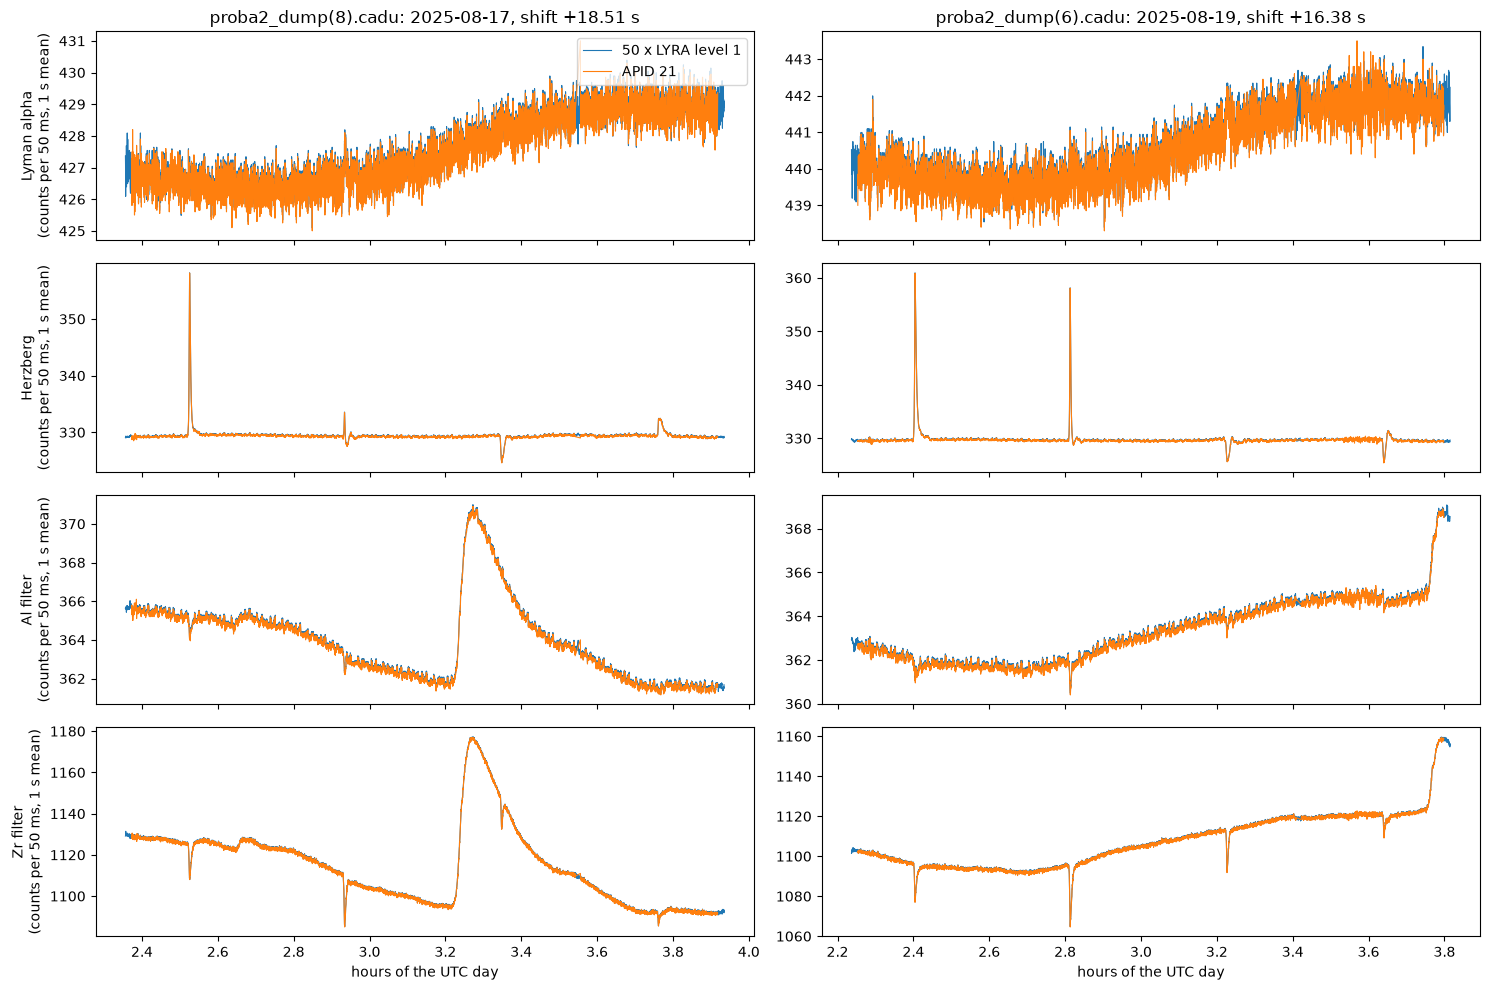

In [30]:
def per_second(seconds: np.ndarray, values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Mean of the values over each whole second."""
    index = np.floor(seconds).astype(int)
    index -= index.min()
    totals, number = np.bincount(index, values), np.bincount(index)
    kept = number > 0
    return np.flatnonzero(kept) + np.floor(seconds.min()) + 0.5, totals[kept] / number[kept]


fig, axes = plt.subplots(CHANNELS, 2, figsize=(15, 10), sharex="col")
for column, dump in enumerate(["proba2_dump(8).cadu", "proba2_dump(6).cadu"]):
    day, level1_s, level1_k, t, c, shift = results[dump]
    window = (level1_s >= t[0] - shift - 60) & (level1_s <= t[-1] - shift + 60)
    for channel in range(CHANNELS):
        ax = axes[channel, column]
        level1_mean = per_second(level1_s[window], COUNTS_PER_KHZ * level1_k[channel][window])
        apid_mean = per_second(t - shift, c[channel])
        ax.plot(level1_mean[0] / 3600, level1_mean[1], linewidth=0.8, label="50 x LYRA level 1")
        ax.plot(apid_mean[0] / 3600, apid_mean[1], linewidth=0.8, label="APID 21")
        if column == 0:
            ax.set_ylabel(f"{channel_names[channel]}\n(counts per 50 ms, 1 s mean)")
    axes[0, column].set_title(f"{dump}: {day:%Y-%m-%d}, shift {shift:+.2f} s")
    axes[-1, column].set_xlabel("hours of the UTC day")
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
plt.show()

What the three dumps give:

* **The scale is the same for all three**, with no fitting: the slope of APID 21 against level 1 is
  50.0 in the zirconium channel (r = 0.996 to 0.998) and 50.1 to 50.2 in aluminium (r = 0.98 to 0.99). In the UV channels (Herzberg
  and Lyman alpha), where LYRA varies by only 1 to 2 counts, r is 0.86 to 0.97 and the slope 50.3 to 52.
* **The mean difference from 50 times level 1 is the same in every dump**: -0.09, -0.07, -0.08 and -0.23 counts for channels 0 to 3, and so
  is the residual (1.2, 0.65, 0.4 and 1.6 counts rms), whatever the day or the level of the channel (the zirconium channel changes
  by 13 to 19 counts rms in the dumps, and the residual does not). So the difference is a fixed property of the two readouts (the
  level 1 numbers are whole counts plus a fixed fraction per channel, and the APID 21 samples are not the same instants of
  the 50 ms), not a mismatch of the signal.
* **Two more flares and more features, all in both**: in dump 8 a flare (Al 362 to 371 and Zr 1095 to 1177 counts at 3.22 h, with the
  decay over the next 0.4 h), in dump 6 the start of one (3.77 h, Al +4 and Zr +40 counts), and the Herzberg spikes and the Zr dips
  of dump 10 again (at 2.53 h and 2.93 h in dump 8, at 2.41 h and 2.81 h in dump 6). A dark or offset value would not respond to a flare.
* **The shift of the clock is not the same**: +21.11 s on 2025-08-14, +18.51 s on 08-17 and +16.38 s on 08-19, each sharp as in
  section 9. It falls by about 0.9 s per day, which is a drift of about 10 ppm of the on-board tick clock against the GPS-derived offset
  of APID 18 (a single offset has been used for all the dumps). With the 18 s of the leap seconds taken out, the clock
  is +3.1, +0.5 and -1.6 s from UTC. This does not change the identification, but a time from an APID 21 packet is only good to a few
  seconds with the single offset, and the shift has to be found against LYRA if more is needed.


## 11. What we know so far

* APID 21 is 697 packets in three dumps (6, 8, 10), one every 50 s, 99.9 % with a valid CRC-16.
* A packet has a 20 Hz **sample counter** (first and last value, 1000 apart, the next packet starts 2 after) and a
  block compressed with the Unix `compress` program, decoded here.
* The decompressed block (8071 bytes) is 4 channels of 501 samples (a first value then 500 first differences, 3 bytes
  each, 10 samples per second), 500 flag words of 4 bytes (all 2), the first counter again, and 5 (sometimes 6) time
  marks (tick, fraction, counter) 10 s and 200 counts apart.
* 4 of the packets are another kind of record in the same wrapper (bytes 40-41 are `0x195A`); not decoded.
* The channels sit at flat levels (about 435, 330, 360, 1100 counts) with a slow drift and no solar signal. **LYRA
  is the best candidate so far** by structure, but the content is not that of an illuminated detector.
* Nothing about the position of the Sun or the attitude.
* The eclipse dump (2026-08-12) has 40 APID 21 packets, all damaged (no CRC passes, 3.5 kB blocks over lost frames). Decoded
  up to the first error, they show the same flat levels as the other dumps and no eclipse dip, but only a fifth of the
  window is recoverable (section 6).
* Against the LYRA data of that day (sunpy, section 8): channel 0 of the eclipse dump has one fragment in the eclipse, at its
  start, 2.3 % lower, as LYRA's aluminium and zirconium channels fall (1 % and 9.5 %). The correlation of all the recovered
  samples is positive (+0.78) but not significant. A lead, not a proof.
